# Regresión Logística y Validación Cruzada

### Jorge Tello 664317

### Lenguaje utilizado: Python


<div style="page-break-before: always;"></div>


## Indíce
1. Introducción
2. Objetivos
3. Definición del problema de clasificación
4. Separación de datos y balance de clases
5. Evaluación mediante validación cruzada
6. Entrenamiento final y evaluación en prueba
7. Curva ROC y AUC
8. Interpretación del modelo
9. Conclusiones
10. Referencias

<div style="page-break-before: always;"></div>


## Introducción
En años recientes, la diabetes se ha convertido en una de las condiciones crónicas de mayor prevalencia a nivel global, y su 
detección oportuna permite intervenciones que reducen significativamente el riesgo de 
complicaciones a largo plazo (OMS, 2024). La identificación temprana de individuos en riesgo, a partir 
de indicadores de salud y hábitos que son relativamente sencillos de recolectar, representa 
una herramienta valiosa de apoyo en salud pública.

En este análisis se utiliza el *Diabetes Health Indicators Dataset*, derivado de la encuesta 
BRFSS (Behavioral Risk Factor Surveillance System. CDC, 2015), el cual contiene 253,680 
observaciones y 21 variables relacionadas con indicadores de salud, hábitos y condiciones 
socioeconómicas de los encuestados. A partir de este conjunto de datos se construye una 
variable de salida binaria que indica si un individuo presenta o no riesgo de diabetes, y se 
desarrolla un modelo de regresión logística para predecirla.

El presente reporte documenta la definición del problema de clasificación, la separación de 
los datos, la evaluación del modelo mediante validación cruzada, su desempeño en un conjunto 
de prueba independiente, y la interpretación de los coeficientes obtenidos, de forma que los 
resultados y conclusiones puedan comprenderse en su totalidad sin necesidad de revisar el código.

## Objetivos

**Objetivo general**

Desarrollar y evaluar un modelo de regresión logística para clasificar el riesgo de diabetes 
de un individuo a partir de indicadores de salud, comparando su desempeño mediante validación 
cruzada y en un conjunto de prueba independiente.

**Objetivos específicos**

- Definir una variable de salida cualitativa a partir de los datos disponibles, justificando el 
  criterio utilizado.
- Separar el conjunto de datos en subconjuntos de entrenamiento y prueba, verificando que el 
  balance de clases se conserve entre ambos.
- Estimar el desempeño del modelo mediante validación cruzada utilizando únicamente los datos 
  de entrenamiento.
- Entrenar el modelo final con la totalidad de los datos de entrenamiento y evaluar su desempeño 
  en el conjunto de prueba, incluyendo la matriz de confusión y métricas de calidad bajo distintos 
  umbrales de decisión.
- Construir la curva ROC y calcular el AUC para evaluar la capacidad discriminativa del modelo.
- Interpretar los coeficientes del modelo en términos de dirección y magnitud de su efecto sobre 
  la probabilidad de riesgo de diabetes.



## Definición del problema de clasificación

### Análisis breve de los datos

El *Diabetes Health Indicators Dataset* contiene 253,680 observaciones y 21 variables 
predictoras relacionadas con indicadores de salud, hábitos de vida y condiciones 
socioeconómicas. La variable original `Diabetes_012` distingue tres categorías: sin diabetes 
(84.2%), prediabetes (1.8%) y diabetes (13.9%), lo que evidencia un fuerte desbalance de clases 
en la población completa.

Un análisis exploratorio de correlaciones muestra que las variables con mayor asociación con 
la condición de diabetes son el estado de salud general autopercibido (`GenHlth`), la presencia 
de presión arterial alta (`HighBP`), el índice de masa corporal (`BMI`) y la dificultad para 
caminar (`DiffWalk`), lo cual es consistente con los factores de riesgo comunmente asociados (National Institute of Diabetes and Digestive and Kidney Diseases [NIDDK], 2016). No se detectaron valores faltantes en el dataset.

### Construcción de la variable de salida

Dado que el objetivo es abordar un problema de clasificación binaria, se colapsan las categorías 
"prediabetes" y "diabetes" en una sola clase positiva, quedando la variable de salida definida 
como:

$$Y = \begin{cases} 0 & \text{sin diabetes} \\ 1 & \text{prediabetes o diabetes} \end{cases}$$


**Justificación**
Tanto la prediabetes como la diabetes representan un riesgo metabólico que amerita seguimiento médico, mientras que la categoría "sin diabetes" es la única verdaderamente negativa. De esta forma, el problema se reduce a una pregunta binaria clínicamente relevante, si el individuo presenta o no riesgo de diabetes.

### Muestreo


Debido al tamaño del dataset original, se trabaja con una muestra aleatoria simple de 25,368 
observaciones, correspondiente al 10% de la población, lo cual permite un manejo computacional 
ágil sin comprometer la representatividad de los datos. 

La Tabla 1 muestra que la distribución de clases en la muestra es prácticamente idéntica a la de la población completa, tanto para la 
variable original de tres clases como para la variable binaria construida.

**Tabla 1.** Comparación del balance de clases entre la población y la muestra

| Clase | Población (253,680) | Muestra (25,368) |
|---|---|---|
| Sin diabetes (0) | 84.24% | 84.36% |
| Prediabetes (1) | 1.83% | 1.86% |
| Diabetes (2) | 13.93% | 13.77% |
| **Sin diabetes (binario 0)** | **84.24%** | **84.36%** |
| **Prediabetes o diabetes (binario 1)** | **15.76%** | **15.64%** |

Esta consistencia confirma que la muestra es adecuada para continuar con el análisis, 
preservando el desbalance característico del fenómeno estudiado.

In [6]:
import pandas as pd

df = pd.read_csv('diabetes_012_health_indicators_BRFSS2015.csv')

sample = df.sample(n=25368, random_state=42).reset_index(drop=True)
sample['Diabetes_binary'] = (sample['Diabetes_012'] > 0).astype(int)
sample = sample.drop(columns=['Diabetes_012'])

import pandas as pd

print(f"Muestra aleatoria: {sample.shape[0]} filas ({sample.shape[0]/df.shape[0]*100:.1f}% de la población)")

print("Variable binaria creada: 0 = sin diabetes, 1 = prediabetes o diabetes")


Muestra aleatoria: 25368 filas (10.0% de la población)
Variable binaria creada: 0 = sin diabetes, 1 = prediabetes o diabetes




## Separación de datos y balance de clases

El conjunto de datos se dividió en un subconjunto de entrenamiento (80%) y uno de prueba (20%), 
utilizando muestreo estratificado respecto a la variable de salida. Se optó por esta proporción 
dado el tamaño de la muestra (25,368 observaciones), lo cual maximiza los datos disponibles para 
el entrenamiento del modelo mientras se mantiene un conjunto de prueba (5,074 observaciones) 
suficientemente grande para obtener estimaciones confiables de las métricas de desempeño.

El muestreo estratificado es particularmente importante en este problema debido al desbalance 
de clases observado (84.4% sin diabetes vs. 15.6% con riesgo de diabetes): una partición 
completamente aleatoria podría, por azar, generar subconjuntos con proporciones de clase 
distintas entre sí, lo cual introduciría sesgos al comparar el desempeño del modelo entre 
entrenamiento y prueba. Al estratificar, se garantiza que ambos subconjuntos reflejen fielmente 
la distribución de clases de la muestra original.

La Tabla 2 confirma que el balance de clases se conserva de manera consistente entre la muestra 
completa, el conjunto de entrenamiento y el conjunto de prueba.

**Tabla 2.** Balance de clases entre la muestra completa y los subconjuntos de entrenamiento y prueba

| Clase | Muestra completa (25,368) | Entrenamiento (20,294) | Prueba (5,074) |
|---|---|---|---|
| Sin diabetes (0) | 84.36% (21,401) | 84.36% (17,120) | 84.37% (4,281) |
| Prediabetes o diabetes (1) | 15.64% (3,967) | 15.64% (3,174) | 15.63% (793) |

In [9]:
from sklearn.model_selection import train_test_split

X = sample.drop(columns=['Diabetes_binary'])
y = sample['Diabetes_binary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Entrenamiento: {X_train.shape[0]} obs. | Prueba: {X_test.shape[0]} obs.")
print("\nBalance de clases (%):")
print("Muestra completa:\n", (y.value_counts(normalize=True).sort_index()*100).round(2))


Entrenamiento: 20294 obs. | Prueba: 5074 obs.

Balance de clases (%):
Muestra completa:
 Diabetes_binary
0    84.36
1    15.64
Name: proportion, dtype: float64



## Evaluación mediante validación cruzada

Utilizando exclusivamente los datos de entrenamiento (20,294 observaciones), se estimó el 
desempeño esperado del modelo de regresión logística mediante **validación cruzada 
estratificada de 5 folds (5-fold stratified cross-validation)**. En cada iteración, el modelo se 
entrena con 4 de los 5 folds y se valida con el fold restante, repitiendo el proceso hasta que 
cada fold ha sido usado exactamente una vez como conjunto de validación. La estratificación 
asegura que la proporción de clases (84.4% / 15.6%) se mantenga consistente en cada fold, lo cual 
es relevante dado el desbalance de clases presente en los datos.

Las variables predictoras se estandarizaron (media 0, desviación estándar 1) antes de ajustar el 
modelo, dado que combinan escalas muy distintas (variables binarias 0/1 junto con variables como 
`BMI`, `MentHlth` o `PhysHlth` en rangos más amplios).



In [10]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
results = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)

for m in scoring:
    vals = results[f'test_{m}']
    print(f"{m}: mean={vals.mean():.4f}  std={vals.std():.4f}")

specs = []
for train_idx, val_idx in cv.split(X_train, y_train):
    Xtr, Xval = X_train.iloc[train_idx], X_train.iloc[val_idx]
    ytr, yval = y_train.iloc[train_idx], y_train.iloc[val_idx]
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    m.fit(Xtr, ytr)
    tn, fp, fn, tp = confusion_matrix(yval, m.predict(Xval)).ravel()
    specs.append(tn / (tn + fp))
specs = np.array(specs)
print(f"specificity: mean={specs.mean():.4f}  std={specs.std():.4f}")

accuracy: mean=0.8483  std=0.0016
precision: mean=0.5444  std=0.0150
recall: mean=0.1834  std=0.0080
f1: mean=0.2743  std=0.0103
roc_auc: mean=0.8179  std=0.0067
specificity: mean=0.9716  std=0.0012


**Tabla 3.** Métricas de desempeño promedio obtenidas mediante validación cruzada (5 folds)

| Métrica | Media | Desviación estándar |
|---|---|---|
| Accuracy | 84.83% | 0.16% |
| Precision | 54.44% | 1.50% |
| Sensitivity (Recall) | 18.34% | 0.80% |
| Specificity | 97.16% | 0.12% |
| F1 Score | 27.43% | 1.03% |
| AUC | 0.818 | 0.007 |

Los resultados muestran una exactitud (accuracy) alta y consistente entre folds (84.8% ± 0.2%), 
pero esta cifra por sí sola resulta engañosa: la sensibilidad es notablemente baja (18.3%), lo 
que indica que el modelo, con el umbral de decisión predeterminado (0.5), identifica 
correctamente solo a una fracción pequeña de los individuos con riesgo real de diabetes. Esto es 
consecuencia directa del desbalance de clases (84.4%/15.6%): el modelo favorece predecir la clase 
mayoritaria, lo cual se refleja en una especificidad muy alta (97.2%) a costa de la sensibilidad. 
Este hallazgo motivará el análisis de distintos umbrales de decisión en la siguiente sección. El 
AUC (0.818) indica una capacidad discriminativa aceptable del modelo a través de todos los 
posibles umbrales.

La baja variabilidad entre folds (desviaciones estándar menores al 2% en todas las métricas) 
refleja la utilidad de la validación cruzada como estimador robusto del desempeño esperado del 
modelo, pues a diferencia de una única partición entrenamiento-prueba, cuyo resultado dependería de qué 
observaciones específicas cayeron en cada subconjunto, la validación cruzada promedia el 
desempeño sobre múltiples particiones, reduciendo el riesgo de que una partición particularmente 
favorable o desfavorable sesgue la evaluación del modelo.


## Entrenamiento final y evaluación en prueba

Una vez estimado el desempeño esperado mediante validación cruzada, se entrenó el modelo de
regresión logística utilizando la totalidad del conjunto de entrenamiento (20,294 observaciones)
y se evaluó su desempeño en el conjunto de prueba independiente (5,074 observaciones), el cual no
participó en ninguna etapa previa del análisis.

### Matriz de confusión

Con el umbral de decisión estándar (0.5), el modelo produjo la siguiente matriz de confusión
sobre el conjunto de prueba:




TP=143 FP=112 FN=650 TN=4169
Accuracy:    0.8498
Precision:   0.5608
Sensitivity: 0.1803
Specificity: 0.9738
F1:          0.2729
AUC:         0.8197


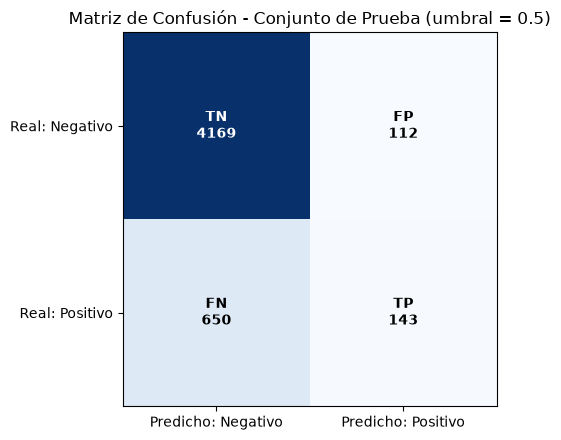

In [13]:
from sklearn.metrics import (confusion_matrix, roc_auc_score, precision_score,
                              recall_score, f1_score, accuracy_score)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

final_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
final_model.fit(X_train, y_train)
y_proba = final_model.predict_proba(X_test)[:, 1]

y_pred = (y_proba >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"TP={tp} FP={fp} FN={fn} TN={tn}")
print(f"Accuracy:    {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision:   {precision_score(y_test, y_pred):.4f}")
print(f"Sensitivity: {recall_score(y_test, y_pred):.4f}")
print(f"Specificity: {tn/(tn+fp):.4f}")
print(f"F1:          {f1_score(y_test, y_pred):.4f}")
print(f"AUC:         {roc_auc_score(y_test, y_proba):.4f}")

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5,4.5))
ax.imshow(cm, cmap='Blues')
labels = [[f'TN\n{cm[0,0]}', f'FP\n{cm[0,1]}'], [f'FN\n{cm[1,0]}', f'TP\n{cm[1,1]}']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, labels[i][j], ha='center', va='center',
                 color='white' if cm[i,j] > cm.max()/2 else 'black', fontweight='bold')
ax.set_xticks([0,1]); ax.set_xticklabels(['Predicho: Negativo','Predicho: Positivo'])
ax.set_yticks([0,1]); ax.set_yticklabels(['Real: Negativo','Real: Positivo'])
ax.set_title('Matriz de Confusión - Conjunto de Prueba (umbral = 0.5)')
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=150)



De los 793 casos con riesgo real de diabetes en el conjunto de prueba, el modelo identificó
correctamente 143 (18.0%), mientras que 650 fueron clasificados erróneamente como negativos. De
los 4,281 casos sin diabetes, clasificó correctamente 4,169 (97.4%).

### Métricas de calidad (umbral = 0.5)

| Métrica | Valor |
|---|---|
| Accuracy | 84.98% |
| Precision | 56.08% |
| Sensitivity (Recall) | 18.03% |
| Specificity | 97.38% |
| F1 Score | 27.29% |
| AUC | 0.820 |

La alta exactitud (85.0%) contrasta con la baja sensibilidad (18.0%), pues el modelo identifica muy
bien a quienes no tienen riesgo de diabetes, pero deja pasar a la mayoría de quienes sí lo tienen.
Esto es consecuencia del desbalance de clases (84.4%/15.6%) presente en los datos.

### Análisis de umbrales de decisión

Para explorar este trade-off, se recalcularon las métricas variando el umbral de decisión entre
0.10 y 0.90 (Figura 2).









Umbral 0.75 -> TP=11 FP=4 FN=782 TN=4277
Precision: 0.7333  Sensitivity: 0.0139


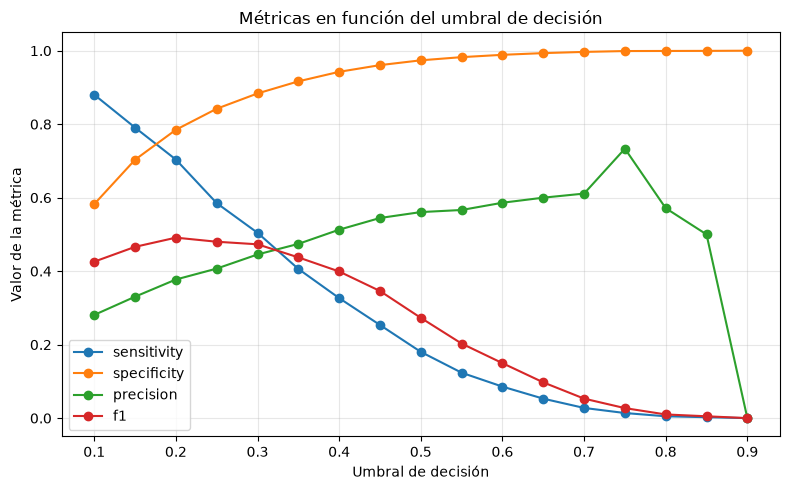

In [15]:
from sklearn.metrics import (confusion_matrix, roc_auc_score, precision_score,
                              recall_score, f1_score, accuracy_score)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

thresholds = np.arange(0.10, 0.95, 0.05)
rows = []
for th in thresholds:
    pred = (y_proba >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append([th, accuracy_score(y_test, pred), precision_score(y_test, pred, zero_division=0),
                 recall_score(y_test, pred, zero_division=0), tn/(tn+fp),
                 f1_score(y_test, pred, zero_division=0)])
umbrales_df = pd.DataFrame(rows, columns=['threshold','accuracy','precision','sensitivity','specificity','f1'])

plt.figure(figsize=(8,5))
for col in ['sensitivity','specificity','precision','f1']:
    plt.plot(umbrales_df['threshold'], umbrales_df[col], marker='o', label=col)
plt.xlabel('Umbral de decisión'); plt.ylabel('Valor de la métrica')
plt.title('Métricas en función del umbral de decisión')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('threshold_analysis.png', dpi=150)

y_pred_075 = (y_proba >= 0.75).astype(int)
tn75, fp75, fn75, tp75 = confusion_matrix(y_test, y_pred_075).ravel()
print(f"\nUmbral 0.75 -> TP={tp75} FP={fp75} FN={fn75} TN={tn75}")
print(f"Precision: {precision_score(y_test, y_pred_075):.4f}  Sensitivity: {recall_score(y_test, y_pred_075):.4f}")

Se observa un trade-off entre flexibilidad y especificidad:

- Con umbrales bajos (ej. 0.10), la sensibilidad es muy alta (88.0%), pero la especificidad cae a
  58.3%, generando muchos falsos positivos.
- Con umbrales altos (ej. 0.70+), ocurre lo contrario: la especificidad supera el 99%, pero la
  sensibilidad se desploma por debajo del 3%.
- El F1 Score se maximiza alrededor de un umbral de 0.20 (F1 = 0.491), con sensibilidad de 70.4%
  y precisión de 37.7%.

### Aclaración sobre el uso de un umbral más estricto

Idealmente, en un contexto clínico de diagnóstico, sería deseable utilizar un umbral 
considerablemente más alto (por ejemplo, 0.75) antes de clasificar a una persona como en riesgo 
de diabetes, ya que esto reduce drásticamente los falsos positivos y aumenta la confianza de cada 
predicción positiva. Sin embargo, al evaluar el modelo con umbral = 0.75 sobre estos datos, la 
matriz de confusión resultante es:

Umbral = 0.75
TP=11 FP=4 FN=782 TN=4277
Accuracy:    0.8451
Precision:   0.7333
Sensitivity: 0.0139
Specificity: 0.9991
F1:          0.0272


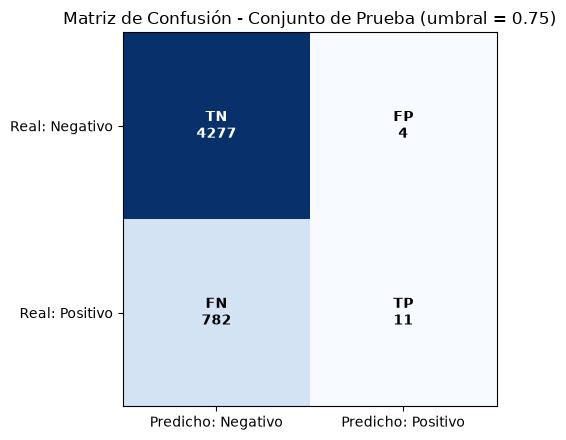

In [16]:
th = 0.75
y_pred_075 = (y_proba >= th).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_075).ravel()
print(f"Umbral = {th}")
print(f"TP={tp} FP={fp} FN={fn} TN={tn}")
print(f"Accuracy:    {accuracy_score(y_test, y_pred_075):.4f}")
print(f"Precision:   {precision_score(y_test, y_pred_075):.4f}")
print(f"Sensitivity: {recall_score(y_test, y_pred_075):.4f}")
print(f"Specificity: {tn/(tn+fp):.4f}")
print(f"F1:          {f1_score(y_test, y_pred_075):.4f}")

cm = confusion_matrix(y_test, y_pred_075)
fig, ax = plt.subplots(figsize=(5,4.5))
ax.imshow(cm, cmap='Blues')
labels = [[f'TN\n{cm[0,0]}', f'FP\n{cm[0,1]}'], [f'FN\n{cm[1,0]}', f'TP\n{cm[1,1]}']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, labels[i][j], ha='center', va='center',
                 color='white' if cm[i,j] > cm.max()/2 else 'black', fontweight='bold')
ax.set_xticks([0,1]); ax.set_xticklabels(['Predicho: Negativo','Predicho: Positivo'])
ax.set_yticks([0,1]); ax.set_yticklabels(['Real: Negativo','Real: Positivo'])
ax.set_title('Matriz de Confusión - Conjunto de Prueba (umbral = 0.75)')
plt.tight_layout(); plt.savefig('confusion_matrix_075.png', dpi=150)

Aunque la precisión sube a 73.3% y la interpretabilidad a 99.9%, la sensibilidad cae a apenas 1.4%,
es decir, el modelo dejaría de detectar a 782 de los 793 casos con riesgo real presentes en el
conjunto de prueba. Dado el desempeño  actual del modelo y el nivel 
de desbalance de los datos, exigir un umbral tan alto no es viable en este caso, pues la ganancia en 
precisión no compensa la pérdida casi total de capacidad de detección. Por esta razón, se 
mantiene el umbral estándar de 0.5 como punto de evaluación del modelo final, reconociendo que 
un ajuste de umbral hacia valores más altos solo sería recomendable si se contara con un modelo 
con mayor poder discriminativo o con variables predictoras adicionales.

### Comparación entre validación cruzada y conjunto de prueba

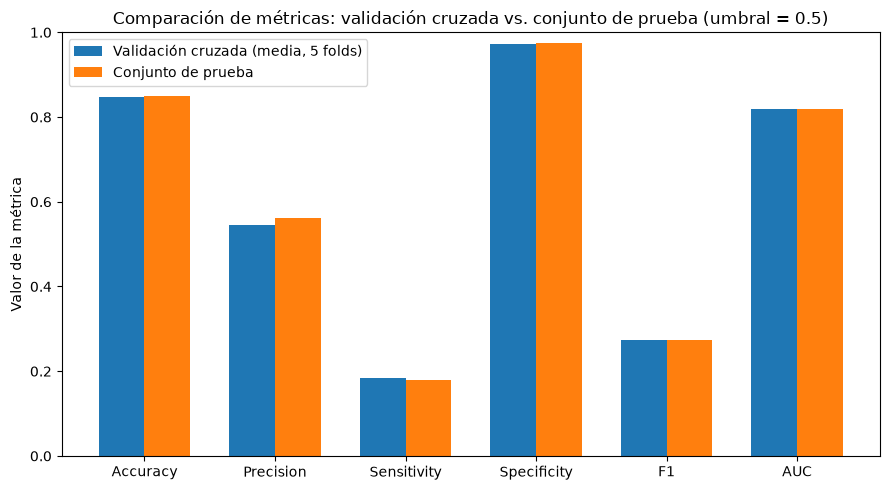

In [17]:
import numpy as np
import matplotlib.pyplot as plt

metricas = ['Accuracy', 'Precision', 'Sensitivity', 'Specificity', 'F1', 'AUC']
cv_vals   = [0.8483, 0.5444, 0.1834, 0.9716, 0.2743, 0.8179]
test_vals = [0.8498, 0.5608, 0.1803, 0.9738, 0.2729, 0.8197]

x = np.arange(len(metricas))
width = 0.35

fig, ax = plt.subplots(figsize=(9,5))
ax.bar(x - width/2, cv_vals, width, label='Validación cruzada (media, 5 folds)')
ax.bar(x + width/2, test_vals, width, label='Conjunto de prueba')
ax.set_xticks(x); ax.set_xticklabels(metricas)
ax.set_ylabel('Valor de la métrica'); ax.set_ylim(0, 1)
ax.set_title('Comparación de métricas: validación cruzada vs. conjunto de prueba (umbral = 0.5)')
ax.legend()
plt.tight_layout()
plt.savefig('cv_vs_test_comparison.png', dpi=150)


| Métrica | Validación cruzada (media) | Conjunto de prueba |
|---|---|---|
| Accuracy | 84.83% | 84.98% |
| Precision | 54.44% | 56.08% |
| Sensitivity | 18.34% | 18.03% |
| Specificity | 97.16% | 97.38% |
| F1 | 27.43% | 27.29% |
| AUC | 0.818 | 0.820 |

Las métricas obtenidas en el conjunto de prueba son consistentes con las estimadas mediante
validación cruzada, con diferencias menores al 1.6% en todos los casos. Esto confirma que la
validación cruzada proporcionó una estimación confiable y no sesgada del desempeño esperado del
modelo, y que este generaliza de forma estable a datos no vistos, por lo que podemos descartar un overfitting.




## Curva ROC y AUC

Para evaluar la capacidad discriminativa del modelo a través de todos los posibles umbrales de
decisión (y no solo en un punto de corte específico), se construyó la curva ROC (Receiver
Operating Characteristic) a partir de las probabilidades estimadas por el modelo sobre el
conjunto de prueba.




AUC: 0.8197


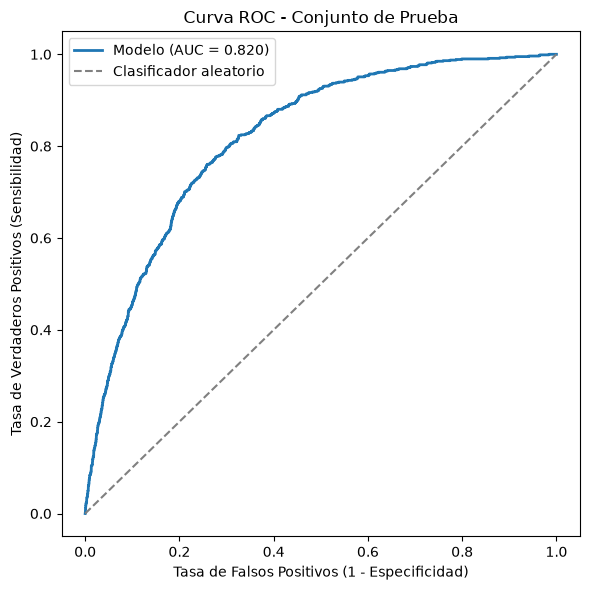

In [18]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
print(f"AUC: {roc_auc:.4f}")

plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f'Modelo (AUC = {roc_auc:.3f})', linewidth=2)
plt.plot([0,1], [0,1], linestyle='--', color='gray', label='Clasificador aleatorio')
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)')
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)')
plt.title('Curva ROC - Conjunto de Prueba')
plt.legend()
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150)

La curva ROC grafica la tasa de verdaderos positivos (sensibilidad) contra la tasa de falsos
positivos (1 − especificidad) para cada umbral posible entre 0 y 1. La línea diagonal representa
el desempeño esperado de un clasificador aleatorio (AUC = 0.5), que no tiene ninguna capacidad de
distinguir clases. La curva del modelo se ubica consistentemente por encima de esta
diagonal, indicando que el modelo discrimina mejor que el azar en todo el rango de umbrales.

### Área bajo la curva (AUC)


In [19]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc_score = auc(fpr, tpr)
print(f"AUC: {auc_score:.4f}")

AUC: 0.8197



$$AUC = 0.820$$

El AUC resume en un solo número el desempeño del modelo considerando todos los umbrales
posibles, a diferencia de métricas como accuracy o sensibilidad, que solo describen el
comportamiento del modelo en un punto de corte específico. Un valor de 0.820 indica que, si se
toma al azar una observación con diabetes/prediabetes y otra sin ella, el modelo asigna una
probabilidad estimada mayor a la observación positiva en aproximadamente el 82% de las veces.
Esto se considera una capacidad discriminativa aceptable, aun cuando, como se 
discutió en la sección anterior, el desbalance de clases dificulta obtener simultáneamente alta
sensibilidad y alta precisión en un único umbral.

Es importante notar que el AUC no se ve afectado por el desbalance de clases de la misma forma
que la exactitud, pues mientras que la accuracy puede resultar engañosamente alta simplemente por la
prevalencia de la clase negativa (84.4%), el AUC evalúa la capacidad del modelo para ordenar
correctamente las observaciones según su riesgo estimado, independientemente de cuántas
observaciones haya de cada clase. Esto lo convierte en una métrica más robusta para resumir el
desempeño global del modelo en este problema.


## Interpretación del modelo

Para interpretar el efecto de cada variable, se extraen los coeficientes ($\beta$) del modelo de
regresión logística final entrenado en el Paso 4, y se calcula el *odds ratio* (OR) de cada uno
como $e^{\beta}$, tal como se definió en la sección de conceptos.

In [20]:
logreg = final_model.named_steps['logisticregression']
coefs = logreg.coef_[0]
intercept = logreg.intercept_[0]
odds_ratios = np.exp(coefs)

coef_table = pd.DataFrame({
    'variable': X.columns,
    'coef_beta': coefs,
    'odds_ratio': odds_ratios
}).sort_values('coef_beta', key=abs, ascending=False)

print(f"Intercepto (beta0): {intercept:.4f}")
print(coef_table.round(4).to_string(index=False))

Intercepto (beta0): -2.2435
            variable  coef_beta  odds_ratio
             GenHlth     0.5676      1.7641
                 BMI     0.3824      1.4659
                 Age     0.3811      1.4639
              HighBP     0.3642      1.4394
            HighChol     0.3464      1.4139
   HvyAlcoholConsump    -0.1884      0.8283
           CholCheck     0.1749      1.1911
              Income    -0.1082      0.8974
                 Sex     0.1071      1.1130
        PhysActivity    -0.0570      0.9446
HeartDiseaseorAttack     0.0548      1.0563
            MentHlth    -0.0523      0.9490
              Fruits    -0.0471      0.9540
            PhysHlth    -0.0379      0.9628
         NoDocbcCost     0.0294      1.0299
             Veggies    -0.0292      0.9712
           Education    -0.0272      0.9731
              Smoker    -0.0254      0.9749
            DiffWalk    -0.0147      0.9854
       AnyHealthcare     0.0071      1.0071
              Stroke     0.0009      1.0009


Dado que las variables predictoras se estandarizaron antes de entrenar el
modelo (media 0, desviación estándar 1), cada coeficiente representa el cambio en el logit de la
probabilidad de riesgo de diabetes asociado a un incremento de una desviación estándar en la
variable correspondiente (y no a una unidad en su escala original). Esto permite además comparar
directamente la magnitud del efecto entre variables, independientemente de su escala.

### Variables con mayor efecto sobre la probabilidad de riesgo

**Tabla 5.** Coeficientes y odds ratios de las variables con mayor efecto (valor absoluto de β)

| Variable | β (estandarizado) | Odds Ratio | Interpretación |
|---|---|---|---|
| GenHlth | 0.568 | 1.76 | Por cada desviación estándar de deterioro en la salud general autopercibida, las probabilidades (*odds*) de riesgo de diabetes aumentan 76% |
| BMI | 0.382 | 1.47 | Por cada desviación estándar de aumento en el índice de masa corporal, las *odds* aumentan 47% |
| Age | 0.381 | 1.46 | Por cada desviación estándar de aumento en la categoría de edad, las *odds* aumentan 46% |
| HighBP | 0.364 | 1.44 | Tener presión arterial alta aumenta las *odds* de riesgo en 44% |
| HighChol | 0.346 | 1.41 | Tener colesterol alto aumenta las *odds* de riesgo en 41% |
| HvyAlcoholConsump | -0.188 | 0.83 | El consumo elevado de alcohol se asocia con una reducción del 17% en las *odds* |

El signo de cada coeficiente indica la dirección del efecto, observamos que las cinco primeras variables
(GenHlth, BMI, Age, HighBP, HighChol) tienen coeficientes positivos, por lo que incrementan la
probabilidad de riesgo de diabetes, mientras que HvyAlcoholConsump tiene un coeficiente negativo.
Este último resultado, aunque puede parecer contraintuitivo, es un hallazgo reportado en otros
estudios epidemiológicos con este mismo dataset, y probablemente refleje un efecto de confusión
socioeconómico (personas con mayores ingresos consumen más alcohol y simultáneamente tienen mejor
acceso a servicios de salud) más que una relación causal, es importante no interpretar los
coeficientes de un modelo observacional, pues correlación no indica causalidad.

### Comparación con la problemática original

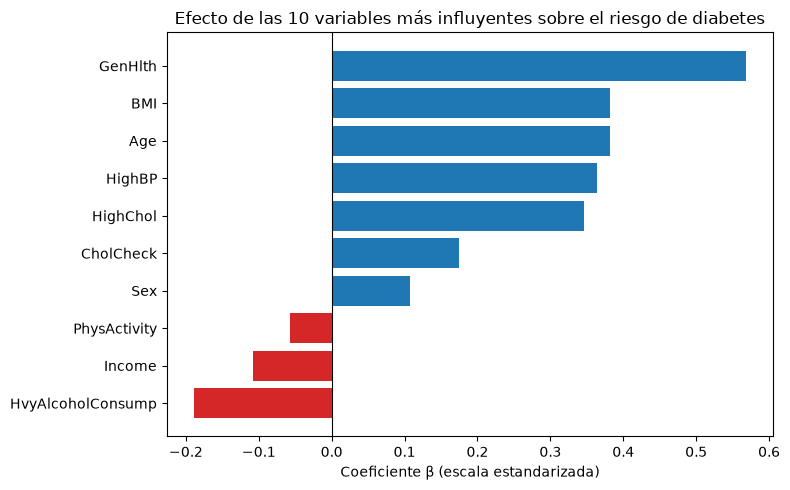

In [21]:
import matplotlib.pyplot as plt

top10 = coef_table.head(10).sort_values('coef_beta')
plt.figure(figsize=(8,5))
colors = ['#d62728' if c < 0 else '#1f77b4' for c in top10['coef_beta']]
plt.barh(top10['variable'], top10['coef_beta'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Coeficiente β (escala estandarizada)')
plt.title('Efecto de las 10 variables más influyentes sobre el riesgo de diabetes')
plt.tight_layout()
plt.savefig('coeficientes.png', dpi=150)


Los resultados obtenidos coinciden con lo descrito anteriormente, la percepción del estado de salud general, el índice de masa corporal, la
edad, la presión arterial alta y el colesterol alto son, en conjunto, los predictores más fuertes
del riesgo de diabetes tipo 2. Esta coherencia respalda la validez del modelo más allá de sus
métricas de desempeño, pues no solo predice razonablemente bien (AUC = 0.820), sino que lo hace 
apoyándose en variables cuya relación con la enfermedad tiene sustento clínico bien establecido, 
lo cual refuerza la confianza en que el modelo capturó relaciones reales.



## Conclusiones

El presente análisis desarrolló y evaluó un modelo de regresión logística para clasificar el
riesgo de diabetes a partir de indicadores de salud.

Los resultados muestran que el modelo alcanza una exactitud alta (85.0%) pero una sensibilidad 
baja (18.0%) con el umbral estándar, y una capacidad discriminativa aceptable (AUC = 0.820). La 
consistencia entre las métricas de validación cruzada y las del conjunto de prueba (diferencias 
menores al 1.6%) confirma que el procedimiento de entrenamiento y evaluación fue correcto y que 
el modelo generaliza de forma estable a datos no vistos, sin evidencia de sobreajuste.

Es importante distinguir entre la validez de la metodología y el desempeño del modelo resultante. 
Que el modelo tenga una sensibilidad limitada no invalida el procedimiento seguido, por el 
contrario, es debido a un correcto procedimiento que esta limitación pudo identificarse y 
cuantificarse con claridad.

La principal limitación identificada, el desbalance de clases (84.4%/15.6%), es una 
característica de los datos; A partir de este hallazgo, existen varias 
líneas de trabajo futuro que podrían mejorar la capacidad de detección del modelo sin comprometer 
la validez del análisis aquí presentado:

- Aplicar técnicas de balanceo de clases (submuestreo de la clase mayoritaria, sobremuestreo de 
  la clase minoritaria, o métodos sintéticos) antes del entrenamiento.
- Ajustar el umbral de decisión de forma explícita según el objetivo de uso del modelo (tamizaje 
  vs. confirmación diagnóstica), en lugar de utilizar el valor predeterminado de 0.5.
- Explorar modelos alternativos (árboles de decisión, random forests, u otros clasificadores no 
  lineales) que puedan capturar relaciones más complejas entre las variables.
- Utilizar el conjunto de datos completo (253,680 observaciones) en lugar de la muestra del 10% 
  utilizada en este análisis, lo cual podría mejorar la estabilidad de las estimaciones.

En términos de interpretación, las variables con mayor efecto sobre la probabilidad de riesgo
(GenHlth, BMI, Age, HighBP y HighChol) son consistentes con los factores de riesgo de diabetes 
reportados en otros estudios(NIDDK, 2025), lo cual respalda que el modelo capturó relaciones reales 
entre las variables y la condición estudiada, más allá de sus métricas de desempeño.

<div style="page-break-before: always;"></div>


## Referencias

* World Health Organization: WHO & World Health Organization: WHO. (2024, 14 noviembre). Diabetes. https://www.who.int/es/news-room/fact-sheets/detail/diabetes
* Síntomas y causas de la diabetes - NIDDK. (s. f.). National Institute Of Diabetes And Digestive And Kidney Diseases. https://www.niddk.nih.gov/health-information/informacion-de-la-salud/diabetes/informacion-general/sintomas-causas
* Teboul, A. (2021). Diabetes Health Indicators Dataset [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset
* Anthropic. (2026). Claude [Modelo de lenguaje grande], Usado en codigo de gráficas. https://claude.ai/
